# 실습01 · 데이터셋 구조·분할·불균형 감사

> 원본 스크립트: `02_응용/01_audit.py` · PPT 15쪽 · TODO A01
>
> 정답 코드를 단계별 셀로 나눈 학습용 노트북이다. 결과는 `outputs/`에 저장한다.

## 학습 목표
- `ImageFolder`가 폴더 이름을 클래스 번호로 바꾸는 규칙(`class_to_idx`)을 확인한다.
- 분할(train/valid/test)마다 클래스 개수와 비율을 따로 센다.
- 파일 바이트의 SHA-256으로 분할 사이 중복 파일이 있는지 감사한다.

## 핵심 개념

| 속성 | 의미 | 예 |
|---|---|---|
| `.classes` | 알파벳 순 클래스 이름 | `["circle", "square", "triangle"]` |
| `.class_to_idx` | 이름 → 번호 | `{"circle": 0, ...}` |
| `.targets` | 파일 순서와 같은 라벨 목록 | `[0, 0, ..., 2]` |
| `.samples` | (경로, 라벨) 목록 | 학습이 아니라 목록 조회 |

In [1]:
# ============================================================
# 0. 노트북 실행 환경 준비
# ============================================================

# 파일·폴더 경로를 객체로 다루는 Path
from pathlib import Path
# 결과 목록을 JSON 파일로 저장
import json
# 수치 배열 계산과 source 가중치(npz) 읽기
import numpy as np
# 결과 표(DataFrame) 생성·CSV 저장
import pandas as pd
# PyTorch: Tensor 연산, 자동 미분, 난수 seed
import torch
# 신경망 층(Conv2d, Linear 등)과 손실 함수
from torch import nn
# data/분할/클래스 폴더 구조를 데이터셋으로 읽는 ImageFolder
from torchvision.datasets import ImageFolder
# 이미지 변환(Resize, ToTensor) 묶음
from torchvision import transforms as tr
# 분류 평가 지표: 정확도, F1, 클래스별 보고서, 혼동행렬
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
# Matplotlib: 노트북 안에 이미지·그래프 표시
import matplotlib.pyplot as plt
# 라벨별 파일 목록을 자동으로 만드는 dict
from collections import defaultdict
# 파일 바이트의 SHA-256 지문 계산
import hashlib

# CPU 스레드 1개, seed 14 고정 -> .py 스크립트와 같은 재현 조건
torch.set_num_threads(1)
torch.manual_seed(14)

# 노트북은 자기 폴더(02_응용/)를 작업 경로로 실행된다
# - DATA : 원본 입력 (읽기만 하고 덮어쓰지 않음)
# - OUT  : 노트북이 만드는 결과물 전용 폴더 (스크립트의 outputs/와 분리)
DATA = Path("data")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

# [0,1] RGB 32×32 -> 소형 source Backbone의 학습 입력 조건
# 주의: ImageNet Normalize는 넣지 않음
transform = tr.Compose([tr.Resize((32, 32)), tr.ToTensor()])
print("torch", torch.__version__, "/ 결과 폴더:", OUT)

torch 2.14.0+cu130 / 결과 폴더: outputs


## 1. ImageFolder가 만든 클래스 계약 확인

transform 없이 읽으면 이미지를 Tensor로 바꾸지 않고 목록만 만든다.

In [2]:
# ============================================================
# 1. 분할별 ImageFolder 생성 및 매핑 확인
# ============================================================

datasets = {split: ImageFolder(DATA / split) for split in ["train", "valid", "test"]}
for split, ds in datasets.items():
    print(f"{split:<5} 파일 {len(ds):>3}개 / class_to_idx {ds.class_to_idx}")

# samples 앞 3개: (경로, 라벨 번호)
for path, label in datasets["train"].samples[:3]:
    print(Path(path).relative_to(DATA), "->", label)

train 파일 180개 / class_to_idx {'circle': 0, 'square': 1, 'triangle': 2}
valid 파일  90개 / class_to_idx {'circle': 0, 'square': 1, 'triangle': 2}
test  파일  30개 / class_to_idx {'circle': 0, 'square': 1, 'triangle': 2}
train/circle/circle_000.png -> 0
train/circle/circle_001.png -> 0
train/circle/circle_002.png -> 0


## 2. TODO A01 · 라벨별 개수와 비율

`targets.count(label)`로 해당 라벨 번호가 몇 번 나오는지 센다.

In [3]:
# ============================================================
# 2. TODO A01: 분할·클래스별 개수와 비율
# ============================================================

rows = []
for split, dataset in datasets.items():
    for label, name in enumerate(dataset.classes):
        # TODO A01: list.count(label) -> 예) train label 0 -> 120
        count = dataset.targets.count(label)
        rows.append({"split": split, "class": name, "n": count, "ratio": count / len(dataset)})

table = pd.DataFrame(rows)
table.to_csv(OUT / "class_counts.csv", index=False)
print(table.round(4).to_string(index=False))

split    class   n  ratio
train   circle 120 0.6667
train   square  40 0.2222
train triangle  20 0.1111
valid   circle  30 0.3333
valid   square  30 0.3333
valid triangle  30 0.3333
 test   circle  10 0.3333
 test   square  10 0.3333
 test triangle  10 0.3333


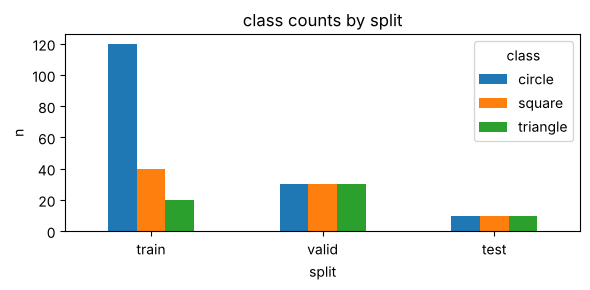

In [4]:
# train만 불균형(6:2:1), valid·test는 균형(1:1:1)인지 그림으로 확인
pivot = table.pivot(index="split", columns="class", values="n").loc[["train", "valid", "test"]]
pivot.plot(kind="bar", figsize=(6, 3), rot=0, title="class counts by split")
plt.ylabel("n")
plt.tight_layout()
plt.show()

## 3. 바이트 동일 중복 감사

같은 SHA-256 지문을 가진 경로가 2개 이상이면 바이트가 완전히 같은 파일이다. test는 이 감사에만 쓰고 성능 계산에는 쓰지 않는다.

In [5]:
# ============================================================
# 3. SHA-256 지문으로 중복 그룹 찾기
# ============================================================

seen = defaultdict(list)
for split, dataset in datasets.items():
    for path, _ in dataset.samples:
        seen[hashlib.sha256(Path(path).read_bytes()).hexdigest()].append(str(Path(path).relative_to(DATA)))

duplicates = [paths for paths in seen.values() if len(paths) > 1]
(OUT / "duplicates.json").write_text(json.dumps(duplicates, ensure_ascii=False, indent=2), encoding="utf-8")
print("지문 수:", len(seen), "/ 파일 수:", sum(len(v) for v in seen.values()))
print("바이트 동일 중복 그룹:", len(duplicates))

지문 수: 300 / 파일 수: 300
바이트 동일 중복 그룹: 0


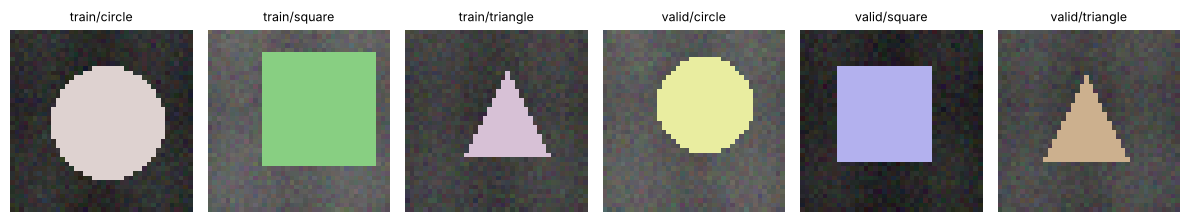

In [6]:
# 분할·클래스별 첫 이미지 미리보기 (40×40 원본)
paths = [datasets[s].samples[datasets[s].targets.index(k)][0] for s in ["train", "valid"] for k in range(3)]
titles = [f"{s}/{c}" for s in ["train", "valid"] for c in datasets["train"].classes]
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, p, t in zip(axes, paths, titles):
    ax.imshow(plt.imread(p))
    ax.set_title(t, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 정리 · README 정답 예와 대조

README 정답 실행 예: train 120·40·20 (0.6667·0.2222·0.1111), valid·test 클래스별 30·10 (0.3333), `바이트 동일 중복 그룹: 0`.

- **클래스 이름을 바꾸면?** `ImageFolder`는 폴더 이름의 알파벳 순서로 번호를 붙인다. 이름이 바뀌면 `class_to_idx`가 바뀌어 저장된 Head 출력 순서·예측 CSV의 번호·지표의 `triangle_recall`(라벨 2) 해석이 모두 어긋난다.
- **train과 valid 비율을 따로 보는 이유:** train 비율은 모델이 학습 중에 받는 편향(circle 66.7%)을, valid 비율은 평가가 클래스마다 같은 비중(33.3%)인지를 보여 준다. 둘을 섞으면 불균형이 학습 문제인지 평가 문제인지 구분할 수 없다.
- **주의:** 바이트 동일 중복 0건은 "완전히 같은 파일이 없다"는 뜻일 뿐, 비슷한 이미지(같은 group_id)가 없다는 뜻은 아니다.